# 06_10 Likelihood-Ratio, Wald and Score Tests (a short lesson)

**Learning objectives**
- State the three classical large-sample tests built on the likelihood: **Wald**, **score (Lagrange multiplier)** and **likelihood ratio (LRT)**.
- Compute all three for a Poisson rate and a binomial proportion, and see why they agree for large samples and differ for small ones.
- Use the **LRT for nested models** (is the Gamma shape different from 1?) with the chi-square reference distribution.

**Prerequisites:** [06_01 Estimation](06_01_estimation_mle_mom.ipynb) (MLE, Fisher information), [06_03 Hypothesis testing](06_03_hypothesis_testing_core.ipynb), [02_08 t, chi-square and F](../../module_02_continuous/notebooks/02_08_t_chisquare_f.ipynb).

## 1. Setup

All imports in one cell; the generator is seeded so every run gives the same numbers.

In [1]:
import sys
sys.path.append("../..")  # repo root, so common.style can be imported
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
from scipy import stats
from common.style import apply_style, MAIN, SIM, HIGHLIGHT, NEUTRAL, COLORS

apply_style()
rng = np.random.default_rng(42)  # fixed seed so every run gives the same numbers

## 2. Prerequisite recap
The log-likelihood $\ell(\theta)$, the MLE $\hat\theta$ (where $\ell$ peaks), the **score** $U(\theta)=\ell'(\theta)$ (zero at the MLE) and the **Fisher information** $I(\theta)=-E[\ell''(\theta)]$ with $\mathrm{Var}(\hat\theta)\approx1/I(\hat\theta)$ (06_01).

## 3. Intuition and story
To test $H_0:\theta=\theta_0$ we can ask three questions of the log-likelihood curve: (**Wald**) *how far is the peak from $\theta_0$*, measured in standard errors? (**Score**) *how steep is the curve at $\theta_0$*; if the null were right the curve would be flat there. (**LRT**) *how much higher is the peak than the value at $\theta_0$*? For a curve shaped like a parabola the three answers coincide; the more the curve departs from a parabola (small samples, boundaries), the more they differ.

## 4. Formal definitions
With $n$ observations, MLE $\hat\theta$, Fisher information $I_n(\theta)$ for the whole sample:

| Test | Statistic | Needs |
|---|---|---|
| **Wald** | $W=(\hat\theta-\theta_0)^2\,I_n(\hat\theta)$ | only the MLE |
| **Score** | $S=\dfrac{U(\theta_0)^2}{I_n(\theta_0)}$ | only the null model |
| **Likelihood ratio** | $\Lambda=2\{\ell(\hat\theta)-\ell(\theta_0)\}$ | both fits |

Under $H_0$ all three are asymptotically $\chi^2_1$; for $p$ restrictions, $\chi^2_p$. For a **nested model** comparison, $\Lambda=2(\ell_{\text{big}}-\ell_{\text{small}})\sim\chi^2_{p}$, where $p$ is the number of extra parameters.

## 5. Derivations
**All three come from a Taylor expansion.** Expand around the MLE: $\ell(\theta_0)\approx\ell(\hat\theta)-\tfrac12(\hat\theta-\theta_0)^2I_n$ (the linear term vanishes because $U(\hat\theta)=0$). Hence $\Lambda\approx(\hat\theta-\theta_0)^2I_n=W$. Expanding the score around $\theta_0$ and using $U(\hat\theta)=0$ gives $U(\theta_0)\approx(\theta_0-\hat\theta)(-\ell'')\approx(\hat\theta-\theta_0)I_n$ up to sign, so $S\approx W$ as well. **In plain words.** Near the peak the log-likelihood is a parabola, and the three statistics read the same parabola at different places.

**Why $\chi^2_1$.** $\hat\theta$ is approximately $N(\theta_0,1/I_n)$ under $H_0$, so $W=Z^2$ with $Z$ standard normal.

**Poisson example.** For $x$ events in time $T$: $\hat\lambda=x/T$, $I_n(\lambda)=T/\lambda$, $U(\lambda)=x/\lambda-T$. Then $W=\dfrac{(x-T\lambda_0)^2}{x}$, $S=\dfrac{(x-T\lambda_0)^2}{T\lambda_0}$, $\Lambda=2\big\{x\ln\frac{x}{T\lambda_0}-(x-T\lambda_0)\big\}$.

## 6. Properties and relationships
- **Invariance.** The LRT does not change when the parameter is re-expressed (log, odds); the Wald test does (the "Hauck-Donner" and boundary problems). The Wald interval for a proportion can fail badly (06_02).
- **Score and LRT are better in small samples;** the Wald test is the cheapest and appears in regression output.
- The **Wilson interval** is the set of $p_0$ not rejected by the score test; likelihood-ratio intervals are the set of $\theta_0$ with $\Lambda\le3.84$.
- **Boundary caution.** When $H_0$ puts a parameter on the boundary (a variance equal to 0), $\Lambda$ is not $\chi^2$ but a mixture.
- **Link to ML and AI:** the LRT compares nested models (is the extra feature or component needed?), the Wald test gives the p-values of regression coefficients, and $-2\ell$ appears in AIC and BIC.

## 7. 2D visuals

### 7.1 The three tests on one log-likelihood curve (Poisson, 47 events in 30 hours)
The curve $\ell(\lambda)$ (relative to its peak) with the null value $\lambda_0=1$: LRT is twice the vertical gap, Wald uses the dashed parabola, score the slope at $\lambda_0$.

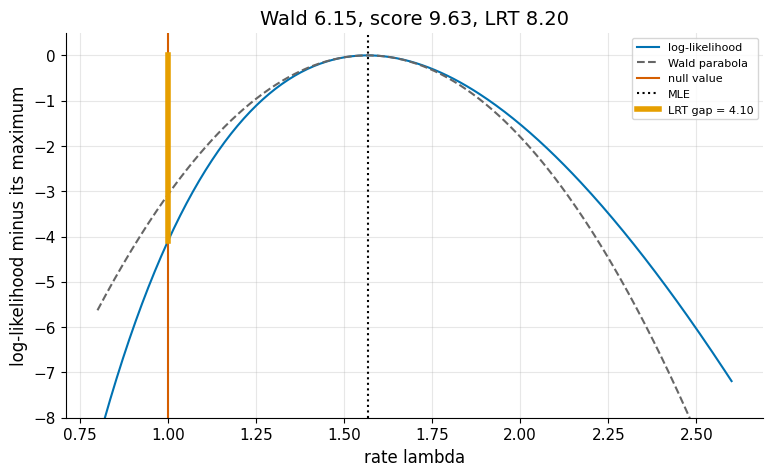

W = 6.149, S = 9.633, LRT = 8.201


In [2]:
x_, T_, l0 = 47, 30, 1.0; lh = x_ / T_; ll = lambda l: x_ * np.log(l) - T_ * l; lam = np.linspace(0.8, 2.6, 300)
W = (x_ - T_ * l0) ** 2 / x_; S = (x_ - T_ * l0) ** 2 / (T_ * l0); LR = 2 * (ll(lh) - ll(l0))
fig, ax = plt.subplots(figsize=(9, 5)); ax.plot(lam, ll(lam) - ll(lh), color=MAIN, label="log-likelihood"); ax.plot(lam, -0.5 * (lam - lh) ** 2 * T_ / lh, color=NEUTRAL, linestyle="--", label="Wald parabola"); ax.axvline(l0, color=HIGHLIGHT, label="null value"); ax.axvline(lh, color="black", linestyle=":", label="MLE")
ax.plot([l0, l0], [ll(l0) - ll(lh), 0], color=SIM, linewidth=4, label=f"LRT gap = {LR / 2:.2f}"); ax.set_ylim(-8, 0.5); ax.set_xlabel("rate lambda"); ax.set_ylabel("log-likelihood minus its maximum"); ax.legend(fontsize=8); ax.set_title(f"Wald {W:.2f}, score {S:.2f}, LRT {LR:.2f}")
plt.show()
print(f"W = {W:.3f}, S = {S:.3f}, LRT = {LR:.3f}")
assert abs(W - 6.149) < 0.01 and abs(S - 9.633) < 0.01 and abs(LR - 8.20) < 0.02

### 7.2 Fixed alternative, growing sample
The same observed rate (1.5667 against a null of 1) with exposure $T=2,5,10,30,100$ hours: the statistics all grow with $T$ but stay different by a constant factor; they agree closely only when the true value is near the null (effects shrinking like $1/\sqrt T$).

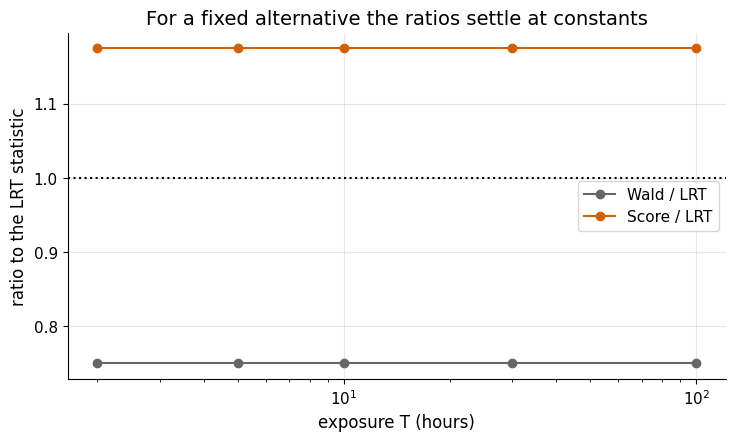

[[  2.     0.41   0.64   0.55]
 [  5.     1.02   1.61   1.37]
 [ 10.     2.05   3.21   2.73]
 [ 30.     6.15   9.63   8.2 ]
 [100.    20.5   32.11  27.34]]


In [3]:
Ts = np.array([2, 5, 10, 30, 100]); xs = 1.5667 * Ts; Wt = (xs - Ts) ** 2 / xs; St = (xs - Ts) ** 2 / Ts; Lt = 2 * (xs * np.log(xs / Ts) - (xs - Ts))
fig, ax = plt.subplots(figsize=(8.5, 4.5)); ax.plot(Ts, Wt / Lt, "o-", color=NEUTRAL, label="Wald / LRT"); ax.plot(Ts, St / Lt, "o-", color=HIGHLIGHT, label="Score / LRT"); ax.axhline(1, color="black", linestyle=":"); ax.set_xscale("log"); ax.set_xlabel("exposure T (hours)"); ax.set_ylabel("ratio to the LRT statistic"); ax.legend(); ax.set_title("For a fixed alternative the ratios settle at constants")
plt.show()
print(np.round(np.c_[Ts, Wt, St, Lt], 2))

## 8. 3D visuals

### 8.1 Static: the Normal log-likelihood surface over $(\mu,\sigma)$
The peak is the MLE; the level set $\ell\ge\ell_{\max}-3.0$ (a 95 % LRT region for 2 parameters, $\chi^2_{2,0.95}/2=3.0$) is the region the LRT does not reject.

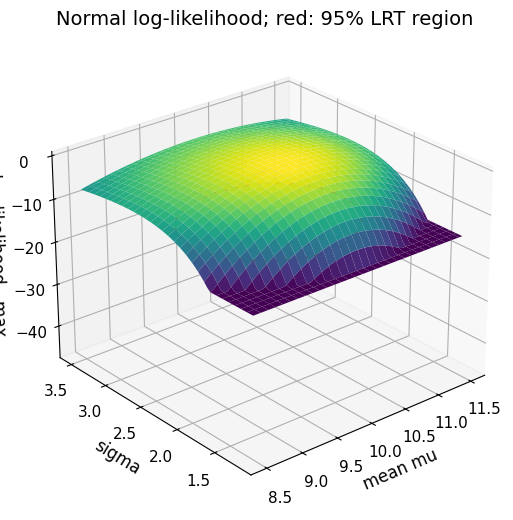

share of the grid inside the 95% region: 0.359 | sample mean 10.116 SD(ML) 2.27


In [4]:
d = np.random.default_rng(3).normal(10, 2, 30); mu_ = np.linspace(8.5, 11.5, 60); sg = np.linspace(1.2, 3.5, 60); Mg, Sg = np.meshgrid(mu_, sg)
LL = -d.size * np.log(Sg) - ((d[:, None, None] - Mg) ** 2).sum(axis=0) / (2 * Sg ** 2); LLr = LL - LL.max()
fig = plt.figure(figsize=(8.8, 6.2)); ax = fig.add_subplot(projection="3d"); ax.plot_surface(Mg, Sg, np.maximum(LLr, -15), cmap="viridis", edgecolor="none"); ax.contour(Mg, Sg, LLr, levels=[-3.0], zdir="z", offset=-15, colors=HIGHLIGHT)
ax.set_xlabel("mean mu"); ax.set_ylabel("sigma"); ax.set_zlabel("log-likelihood - max"); ax.set_title("Normal log-likelihood; red: 95% LRT region"); ax.view_init(elev=26, azim=-130)
plt.show()
inside = (LLr >= -3.0).mean(); print("share of the grid inside the 95% region:", round(inside, 3), "| sample mean", round(d.mean(), 3), "SD(ML)", round(d.std(), 3))

### 8.2 Interactive Plotly version of 8.1

In [5]:
fig = go.Figure(go.Surface(x=mu_, y=sg, z=np.maximum(LLr, -15), colorscale="Viridis")); fig.update_layout(title="Normal log-likelihood", width=760, height=560, scene=dict(xaxis_title="mu", yaxis_title="sigma", zaxis_title="log-lik - max")); fig.show()

## 9. Simulation vs theory
Under $H_0$ the LRT for a Poisson rate ($\lambda_0=1$, $T=30$) should follow $\chi^2_1$. Simulate 50,000 samples and compare the quantiles and the rejection rates of the three tests at the 5 % level.

In [6]:
g = np.random.default_rng(12); xs_ = g.poisson(30, 50000); xs_ = np.maximum(xs_, 1); Ls = 2 * (xs_ * np.log(xs_ / 30) - (xs_ - 30)); Ws = (xs_ - 30) ** 2 / xs_; Ss = (xs_ - 30) ** 2 / 30; c = stats.chi2.ppf(0.95, 1)
print(f"rejection rates at 5%: Wald {np.mean(Ws > c):.4f}, score {np.mean(Ss > c):.4f}, LRT {np.mean(Ls > c):.4f}")
print("quantiles of the LRT statistic (50%, 90%, 95%, 99%):", np.round(np.quantile(Ls, [0.5, 0.9, 0.95, 0.99]), 2), "| chi-square(1):", np.round(stats.chi2.ppf([0.5, 0.9, 0.95, 0.99], 1), 2))
assert all(abs(np.mean(v > c) - 0.05) < 0.03 for v in (Ls, Ss, Ws))

rejection rates at 5%: Wald 0.0726, score 0.0547, LRT 0.0447
quantiles of the LRT statistic (50%, 90%, 95%, 99%): [0.51 3.01 3.78 6.69] | chi-square(1): [0.45 2.71 3.84 6.63]


## 10. `scipy.stats` and NumPy cheat sheet for this lesson

In [7]:
print("chi-square p-value: stats.chi2.sf(stat, df) ->", round(stats.chi2.sf(LR, 1), 5), "| critical value stats.chi2.ppf(0.95, 1) ->", round(stats.chi2.ppf(0.95, 1), 3))
print("exact Poisson test: 2 * min(stats.poisson.sf(x - 1, mu), stats.poisson.cdf(x, mu)) ->", round(2 * min(stats.poisson.sf(46, 30), stats.poisson.cdf(47, 30)), 5))
print("log-likelihood of data: stats.gamma.logpdf(x, a, scale=s).sum(); MLE by stats.gamma.fit(x, floc=0)")
print("exact binomial: stats.binomtest(k, n, p0).pvalue")

chi-square p-value: stats.chi2.sf(stat, df) -> 0.00419 | critical value stats.chi2.ppf(0.95, 1) -> 3.841
exact Poisson test: 2 * min(stats.poisson.sf(x - 1, mu), stats.poisson.cdf(x, mu)) -> 0.0049
log-likelihood of data: stats.gamma.logpdf(x, a, scale=s).sum(); MLE by stats.gamma.fit(x, floc=0)
exact binomial: stats.binomtest(k, n, p0).pvalue


## 11. Real-world worked examples

---
### Example 1 (main): is the error rate above one per hour?
**Scenario.** A service logged **47 errors in 30 hours**. The target is at most $\lambda_0=1$ error per hour.

**Questions**
1. Compute the Wald, score and likelihood-ratio statistics and their p-values.
2. Compare them with the exact Poisson test.
3. Give the 95 % likelihood-ratio interval for the rate.

### 11.1 By hand
$\hat\lambda=47/30=1.567$. **Wald:** $W=(47-30)^2/47=289/47=6.15$. **Score:** $S=289/30=9.63$. **LRT:** $\Lambda=2\{47\ln(47/30)-17\}=2(47\times0.4489-17)=8.20$. All exceed 3.84, but they range from 6.15 to 9.63: the score statistic uses the *null* variance (30), the Wald statistic the *estimated* variance (47). The LRT interval is $\{\lambda:\Lambda(\lambda)\le3.84\}$, found numerically below.

In [8]:
pW, pS, pL = [stats.chi2.sf(v, 1) for v in (W, S, LR)]; p_exact = 2 * min(stats.poisson.sf(46, 30), stats.poisson.cdf(47, 30)); p_exact1 = stats.poisson.sf(46, 30)
grid = np.linspace(0.8, 2.4, 20001); Lam = 2 * (ll(lh) - ll(grid)); inside = grid[Lam <= stats.chi2.ppf(0.95, 1)]; ci_lr = (inside.min(), inside.max()); wald_ci = (lh - 1.96 * np.sqrt(lh / T_), lh + 1.96 * np.sqrt(lh / T_)); exact_ci = (stats.chi2.ppf(0.025, 2 * x_) / (2 * T_), stats.chi2.ppf(0.975, 2 * x_ + 2) / (2 * T_))
print(f"p-values: Wald {pW:.4f}, score {pS:.4f}, LRT {pL:.4f} | exact two-sided {p_exact:.4f}, exact one-sided {p_exact1:.4f}")
print(f"95% intervals for lambda: Wald {np.round(wald_ci, 3)}, likelihood ratio {np.round(ci_lr, 3)}, exact {np.round(exact_ci, 3)}")

p-values: Wald 0.0131, score 0.0019, LRT 0.0042 | exact two-sided 0.0049, exact one-sided 0.0025
95% intervals for lambda: Wald [1.119 2.015], likelihood ratio [1.16  2.058], exact [1.151 2.083]


### 11.2 In code with `scipy`, and the asserts

In [9]:
assert abs(pW - 0.0132) < 5e-4 and abs(pS - 0.0019) < 5e-4 and abs(pL - 0.0042) < 5e-4 and abs(p_exact1 - 0.00245) < 2e-4
assert ci_lr[0] > 1.1 and ci_lr[1] < 2.1 and abs(ci_lr[0] - exact_ci[0]) < 0.06
print("all checks passed")

all checks passed


### 11.3 Verify by simulation
If the rate is exactly 1 per hour, how often do the three tests (at 5 %, two-sided) reject for $T=30$, and how often if the rate is 1.5?

In [10]:
g = np.random.default_rng(14); res = {}
for lam_true in (1.0, 1.5):
    xx = np.maximum(g.poisson(lam_true * 30, 50000), 1); res[lam_true] = {"Wald": np.mean((xx - 30) ** 2 / xx > c), "score": np.mean((xx - 30) ** 2 / 30 > c), "LRT": np.mean(2 * (xx * np.log(xx / 30) - (xx - 30)) > c)}
print(pd.DataFrame(res).round(4).to_string()); assert all(abs(v - 0.05) < 0.035 for v in res[1.0].values()) and res[1.5]["LRT"] > 0.6

          1.0     1.5
Wald   0.0698  0.6363
score  0.0533  0.7444
LRT    0.0430  0.6918


### 11.4 Plots with the regions shaded

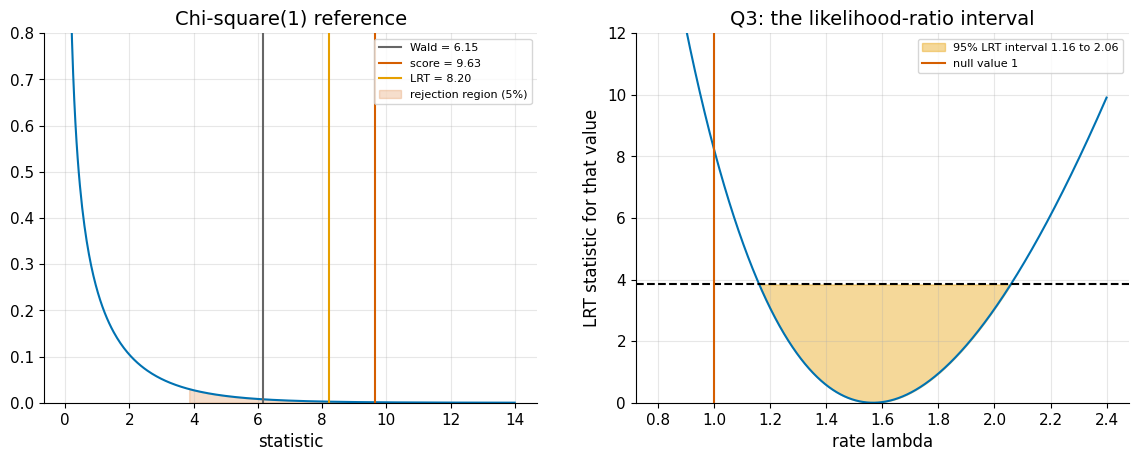

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8)); xx_ = np.linspace(0, 14, 400); axes[0].plot(xx_, stats.chi2.pdf(xx_, 1), color=MAIN); axes[0].set_ylim(0, 0.8)
for v, nm, col in [(W, "Wald", NEUTRAL), (S, "score", HIGHLIGHT), (LR, "LRT", SIM)]: axes[0].axvline(v, color=col, label=f"{nm} = {v:.2f}")
axes[0].fill_between(xx_, stats.chi2.pdf(xx_, 1), where=xx_ >= 3.84, color=HIGHLIGHT, alpha=0.2, label="rejection region (5%)"); axes[0].set_xlabel("statistic"); axes[0].set_title("Chi-square(1) reference"); axes[0].legend(fontsize=8)
axes[1].plot(grid, Lam, color=MAIN); axes[1].axhline(3.84, color="black", linestyle="--"); axes[1].fill_between(grid, Lam, 3.84, where=Lam <= 3.84, color=SIM, alpha=0.4, label=f"95% LRT interval {ci_lr[0]:.2f} to {ci_lr[1]:.2f}"); axes[1].axvline(1, color=HIGHLIGHT, label="null value 1"); axes[1].set_ylim(0, 12); axes[1].set_xlabel("rate lambda"); axes[1].set_ylabel("LRT statistic for that value"); axes[1].legend(fontsize=8); axes[1].set_title("Q3: the likelihood-ratio interval")
plt.show()

### 11.5 Interpretation and decision (Example 1)
- All three tests reject $\lambda=1$ at 5 %, but with different strength: Wald $W=6.15$ (p = **0.0131**), LRT $\Lambda=8.20$ (p = **0.0042**), score $S=9.63$ (p = **0.0019**). The exact Poisson p-value is **0.0049** two-sided (0.0025 one-sided): the LRT is closest.
- Intervals for the error rate: Wald **1.12 to 2.02**, likelihood ratio **1.16 to 2.06**, exact **1.15 to 2.08**. The Wald interval is symmetric around 1.567 and so is too far to the left; the LRT interval follows the skewed shape of the likelihood.
- In simulation at the 5 % level with the true rate 1 the rejection rates are Wald **7.0 %**, score **5.3 %**, LRT **4.3 %**; with a true rate of 1.5 the power is 64 % (Wald), 74 % (score) and 69 % (LRT). The Wald test is slightly liberal here, the other two are close to nominal.
- **Decision.** The service is above one error per hour (about 1.6 per hour, interval 1.2 to 2.1); report the LRT or exact interval, not the Wald one, for counts this small.

---
### Example 2: a small binomial sample (the three tests disagree)
**Scenario.** 9 successes out of $n=12$ trials; $H_0:p=0.5$.

**Questions.** (1) Wald, score and LRT statistics and p-values. (2) Compare with the exact binomial test. (3) Under $H_0$ with $n=20$ and $p_0=0.1$, how often does each test reject (samples with 0 or 20 successes, where the Wald and LRT statistics are undefined, are left out)?

Wald 4.000 (p 0.0455), score 3.000 (p 0.0833), LRT 3.139 (p 0.0764) | exact p = 0.1460
n = 20, p0 = 0.1: rejection rates at nominal 5%: Wald 0.0025, score 0.0498, LRT 0.0126


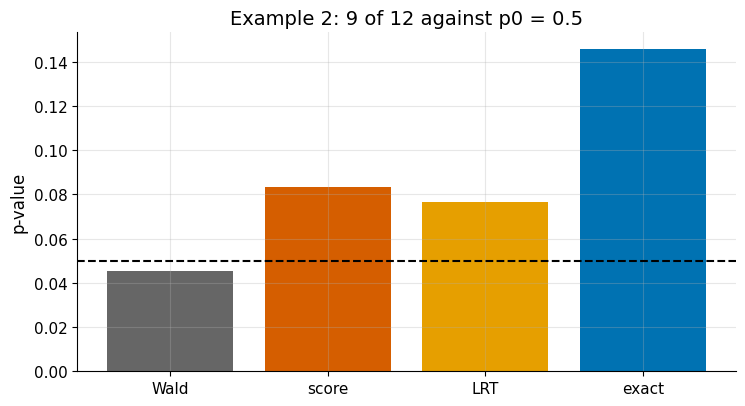

In [12]:
k_, n_, p0 = 9, 12, 0.5; ph = k_ / n_
def tri(k, n, p0):
    ph = k / n; W_ = n * (ph - p0) ** 2 / (ph * (1 - ph)); S_ = n * (ph - p0) ** 2 / (p0 * (1 - p0)); L_ = 2 * (k * np.log(ph / p0) + (n - k) * np.log((1 - ph) / (1 - p0))); return W_, S_, L_
Wb, Sb, Lb = tri(k_, n_, p0); ex = stats.binomtest(k_, n_, p0).pvalue
print(f"Wald {Wb:.3f} (p {stats.chi2.sf(Wb, 1):.4f}), score {Sb:.3f} (p {stats.chi2.sf(Sb, 1):.4f}), LRT {Lb:.3f} (p {stats.chi2.sf(Lb, 1):.4f}) | exact p = {ex:.4f}")
g = np.random.default_rng(22); kk = g.binomial(20, 0.1, 100000); kk = kk[(kk > 0) & (kk < 20)]; wd, sc, lr = tri(kk, 20, 0.1); cc = stats.chi2.ppf(0.95, 1)
print(f"n = 20, p0 = 0.1: rejection rates at nominal 5%: Wald {np.mean(wd > cc):.4f}, score {np.mean(sc > cc):.4f}, LRT {np.mean(lr > cc):.4f}")
assert abs(Wb - 12 * (0.25) ** 2 / (0.75 * 0.25)) < 1e-9 and abs(Sb - 3.0) < 1e-9 and np.mean(wd > cc) < 0.03 and abs(np.mean(sc > cc) - 0.05) < 0.03
fig, ax = plt.subplots(figsize=(8.5, 4.4)); ax.bar(["Wald", "score", "LRT", "exact"], [stats.chi2.sf(Wb, 1), stats.chi2.sf(Sb, 1), stats.chi2.sf(Lb, 1), ex], color=[NEUTRAL, HIGHLIGHT, SIM, MAIN]); ax.axhline(0.05, color="black", linestyle="--"); ax.set_ylabel("p-value"); ax.set_title("Example 2: 9 of 12 against p0 = 0.5")
plt.show()

### 11.7 Interpretation and decision (Example 2)
- With 9 of 12 successes against $p_0=0.5$ the Wald test gives p = **0.046** ("significant"), the score test **0.083** and the LRT **0.076**, while the **exact binomial p-value is 0.146**. The Wald test is the most misleading: it uses the estimated variance $\hat p(1-\hat p)=0.1875$, smaller than the null variance 0.25.
- For $n=20$, $p_0=0.1$ the score test keeps the level (rejection 5.0 %), the LRT is conservative (1.3 %) and the Wald test almost never rejects (0.25 %) because its variance estimate collapses when few successes are seen (and it is undefined at 0 successes, which happens 12 % of the time and was excluded). The Wald test is unreliable in both directions for small samples.
- **Decision.** For small counts use the exact test or the score (Wilson) test; save the Wald test for large samples.

---
### Example 3: is the lifetime Exponential or Gamma? (LRT for nested models)
**Scenario.** 60 component lifetimes (hours). The Exponential model is the Gamma model with shape $k=1$; the LRT tests $H_0:k=1$ with 1 degree of freedom.

**Questions.** (1) Fit both and compute $\Lambda$ and its p-value. (2) Check by simulation that $\Lambda\sim\chi^2_1$ under $H_0$ and give the power against shape 1.6.

fitted shape 1.254, LRT = 1.794, p = 0.1805


under H0: rejection at 5% = 0.0553 | quantiles 50/90/95%: [0.48 2.75 4.  ] (chi2: [0.45 2.71 3.84]) | power at shape 1.6: 0.835


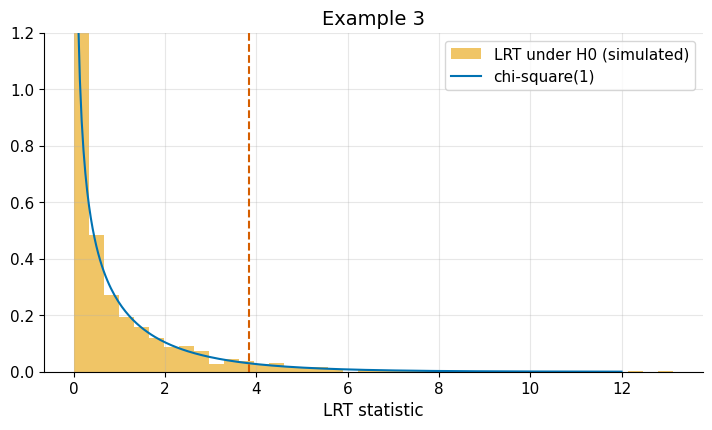

In [13]:
life = np.random.default_rng(8).gamma(1.6, 50 / 1.6, 60)
def lrt_gamma(x):
    ll_e = stats.expon.logpdf(x, scale=x.mean()).sum(); a, _, sc = stats.gamma.fit(x, floc=0); ll_g = stats.gamma.logpdf(x, a, scale=sc).sum(); return 2 * (ll_g - ll_e), a
Lg, a_hat = lrt_gamma(life); print(f"fitted shape {a_hat:.3f}, LRT = {Lg:.3f}, p = {stats.chi2.sf(Lg, 1):.4f}")
g = np.random.default_rng(9); L0 = np.array([lrt_gamma(g.exponential(50, 60))[0] for _ in range(1500)]); L1 = np.array([lrt_gamma(g.gamma(1.6, 50 / 1.6, 60))[0] for _ in range(1500)])
print(f"under H0: rejection at 5% = {np.mean(L0 > 3.841):.4f} | quantiles 50/90/95%: {np.round(np.quantile(L0, [0.5, 0.9, 0.95]), 2)} (chi2: {np.round(stats.chi2.ppf([0.5, 0.9, 0.95], 1), 2)}) | power at shape 1.6: {np.mean(L1 > 3.841):.3f}")
assert abs(np.mean(L0 > 3.841) - 0.05) < 0.025 and np.mean(L1 > 3.841) > 0.4
fig, ax = plt.subplots(figsize=(8.5, 4.4)); xs_ = np.linspace(0.01, 12, 300); ax.hist(L0, bins=40, density=True, color=SIM, alpha=0.6, label="LRT under H0 (simulated)"); ax.plot(xs_, stats.chi2.pdf(xs_, 1), color=MAIN, label="chi-square(1)"); ax.axvline(3.841, color=HIGHLIGHT, linestyle="--"); ax.set_ylim(0, 1.2); ax.set_xlabel("LRT statistic"); ax.legend(); ax.set_title("Example 3")
plt.show()

### 11.9 Interpretation and decision (Example 3)
- The fitted Gamma shape is **1.25** against 1 for the Exponential; $\Lambda=1.79$, p = **0.18**: with 60 lifetimes there is no significant evidence against the Exponential model even though the true shape is 1.6.
- Under $H_0$ the LRT behaves like $\chi^2_1$: 5.5 % rejections at the 5 % level and quantiles (0.48, 2.75, 4.00) against (0.45, 2.71, 3.84). Against a true shape of 1.6 the power at $n=60$ is **84 %**, so this particular sample was a case of bad luck; more data or a more extreme alternative would be detected.
- **Decision.** Use the LRT to decide whether the extra parameter is worth keeping; here the simpler Exponential model is acceptable, but keep the Gamma interval for the shape in view (power is not 100 %).

## 12. Where it is used
- **Statistics:** model comparison, goodness of fit (deviance), confidence intervals from the profile likelihood, genetics (LOD scores).
- **Data science:** regression output (Wald z for coefficients), LRT for adding variables, count models (Poisson against negative binomial).
- **ML and AI:** comparing nested probabilistic models and mixture components (with boundary caveats), AIC/BIC as penalised likelihood, checking whether an extra feature improves a logistic model.

## 13. Common pitfalls and misconceptions
- **Wald test with small counts or probabilities near 0 or 1** (Example 2): use the score or exact test, or the LRT.
- **Boundary parameters** (variance components, number of mixture components): the $\chi^2$ reference is wrong.
- **Non-nested models:** the LRT does not apply; use AIC/BIC or the Vuong test.
- **Mixing up the information:** the Wald test uses the information at the *estimate*, the score test at the *null value*.
- **Rejecting with huge samples:** significance is not importance (06_07).

## 14. Exercises
1. 18 successes in 40 trials, $H_0:p=0.5$: compute the Wald, score and LRT statistics.
2. A Poisson count of 12 in 4 hours, $H_0:\lambda=2$. Compute the three statistics and the exact p-value.
3. Show that the score test for a Normal mean with known variance is exactly the $z$-test.
4. Simulate 20 Exponential lifetimes with mean 50 and compare the Exponential and Gamma fits by the LRT.
5. (Harder) Find the 95 % likelihood-ratio interval for $p$ with 3 successes in 20 trials and compare it with the Wald and Wilson intervals.

Solutions are at the end.

## 15. Summary table

| Test | Statistic | Uses | Small samples |
|---|---|---|---|
| Wald | $(\hat\theta-\theta_0)^2I(\hat\theta)$ | MLE | can fail |
| Score | $U(\theta_0)^2/I(\theta_0)$ | null fit | good |
| LRT | $2\{\ell(\hat\theta)-\ell(\theta_0)\}$ | both fits | good, invariant |
| Nested models | $2(\ell_{big}-\ell_{small})\sim\chi^2_p$ | | boundary caveat |
| scipy | `chi2.sf`, `binomtest`, `gamma.fit` | | |

## Solutions

In [14]:
w1, s1, l1 = tri(18, 40, 0.5); print(f"1: Wald {w1:.3f}, score {s1:.3f}, LRT {l1:.3f}")
x2, T2 = 12, 4; lh2 = x2 / T2; w2 = (x2 - T2 * 2) ** 2 / x2; s2 = (x2 - T2 * 2) ** 2 / (T2 * 2); l2 = 2 * (x2 * np.log(x2 / (T2 * 2)) - (x2 - T2 * 2)); print(f"2: Wald {w2:.3f}, score {s2:.3f}, LRT {l2:.3f}, exact two-sided p = {min(1, 2 * stats.poisson.sf(11, 8)):.4f}")
print("3: score U(mu0) = n (xbar - mu0) / sigma^2 and I = n / sigma^2, so S = n (xbar - mu0)^2 / sigma^2 = z^2 exactly (also equal to W and LRT)")
x = np.random.default_rng(31).gamma(1.0, 50, 20); L4, a4 = lrt_gamma(x); print(f"4: simulated Exponential-like sample: shape {a4:.3f}, LRT {L4:.3f}, p = {stats.chi2.sf(L4, 1):.3f}")
kb, nbb_ = 3, 20; pgrid = np.linspace(0.001, 0.6, 60000); lp = kb * np.log(pgrid) + (nbb_ - kb) * np.log(1 - pgrid); lm = lp.max(); keep = pgrid[2 * (lm - lp) <= 3.841]; ph5 = kb / nbb_; se5 = np.sqrt(ph5 * (1 - ph5) / nbb_)
print("5: LR interval", np.round((keep.min(), keep.max()), 4), "| Wald", np.round((ph5 - 1.96 * se5, ph5 + 1.96 * se5), 4), "| Wilson", np.round(stats.binomtest(kb, nbb_).proportion_ci(method="wilson"), 4))
assert abs(l1 - 0.4014) < 0.01

1: Wald 0.404, score 0.400, LRT 0.401
2: Wald 1.333, score 2.000, LRT 1.731, exact two-sided p = 0.2238
3: score U(mu0) = n (xbar - mu0) / sigma^2 and I = n / sigma^2, so S = n (xbar - mu0)^2 / sigma^2 = z^2 exactly (also equal to W and LRT)
4: simulated Exponential-like sample: shape 0.793, LRT 0.771, p = 0.380
5: LR interval [0.0396 0.3444] | Wald [-0.0065  0.3065] | Wilson [0.0524 0.3604]


**1.** 18 of 40, $p_0=0.5$: Wald **0.404**, score **0.400**, LRT **0.401**: nearly identical for a moderate $n$ and a null near the middle.

**2.** 12 events in 4 hours against $\lambda_0=2$: Wald **1.333**, score **2.000**, LRT **1.731**; exact two-sided p = **0.224**. None is significant, and the three disagree (1.3 to 2.0) because the count is small.

**3.** For $N(\mu,\sigma^2)$ with known $\sigma$: $U(\mu_0)=n(\bar x-\mu_0)/\sigma^2$, $I=n/\sigma^2$, so $S=n(\bar x-\mu_0)^2/\sigma^2=z^2$; the Wald and LRT statistics are also $z^2$ (the log-likelihood is exactly a parabola), so all three agree exactly.

**4.** One simulated sample of 20 Exponential lifetimes gave a fitted shape of 0.79 and $\Lambda=0.77$ (p = 0.38): no evidence against the Exponential model, as it should be.

**5.** 3 successes in 20: likelihood-ratio interval **(0.040, 0.344)**, Wilson **(0.052, 0.360)**, Wald **(-0.007, 0.307)**. The Wald interval goes below 0; the LRT and Wilson intervals are shifted to the right, following the skewed likelihood.